```{eval-rst}
:download:`Download notebook <placement.ipynb>`
```

Run this notebook from the project root, or [download the example helpers](../_static/niagara-example-helpers.zip) and extract them beside a downloaded notebook. The helpers are examples, not part of the Niagara wheel.


# Device placement and ownership

A `DevicePlan` assigns homes to whole simulator regions and, when necessary,
individual parameters. Descendants inherit the home of their owning region.

This example builds a stock 64 x 64 float64 Caustics simulator and computes the native reference before migration. With two visible devices, the source runs on `cuda:1` and the remaining regions on `cuda:0`. Otherwise, the code uses one available device. The printed homes identify the configuration being checked.

![Two-GPU image data flow](../_static/guide/multi_gpu_flow.svg)

In [1]:
%matplotlib inline
import caskade
import caustics
import matplotlib.pyplot as plt
import torch
from matplotlib.colors import PowerNorm

import niagara as ng
from examples.niagara_examples.caustics import image_problem

visible_devices = torch.cuda.device_count()
home = torch.device("cuda:0" if visible_devices else "cpu")
source_home = torch.device("cuda:1" if visible_devices >= 2 else home)
problem = image_problem(64, device=home, dtype=torch.float64)
sim, params = problem.model, problem.truth.detach()
native_class = type(sim)
reference = sim(params).detach().cpu()
q_native = params.clone().requires_grad_()
native_loss = sim(q_native).square().sum()
native_gradient = torch.autograd.grad(native_loss, q_native)[0].detach().cpu()
del q_native, native_loss
print(
    {
        "niagara": ng.__version__,
        "caskade": caskade.__version__,
        "caustics": caustics.__version__,
        "torch": str(torch.__version__),
    }
)
print("Visible CUDA devices:", visible_devices)
if visible_devices < 2:
    print("Two-GPU placement is unavailable; this run uses one available device.")

before = tuple(str(param.device) for param in sim.all_params)
try:
    ng.DevicePlan(default="cuda").validate(sim)
except ng.PlacementError as error:
    print("Rejected before migration:", error)
else:
    raise AssertionError("An unindexed CUDA home should be rejected")
assert tuple(str(param.device) for param in sim.all_params) == before

plan = ng.DevicePlan(default=home, modules={sim.source: source_home}, diagnostics=True)
homes = plan.validate(sim)
assert tuple(str(param.device) for param in sim.all_params) == before
print("Validated source home:", homes[sim.source])
placement = ng.assign_devices(sim, plan)
image = sim(params)
assert image.device == home and sim.source.Re.device == source_home
torch.testing.assert_close(image.detach().cpu(), reference, atol=1e-10, rtol=1e-9)
print("Image shape/device:", tuple(image.shape), image.device)
print("Source parameter home:", sim.source.Re.device)

{'niagara': '0.7.0', 'caskade': '1.1.5', 'caustics': '1.7.1', 'torch': '2.12.0+cu126'}
Visible CUDA devices: 2
Rejected before migration: Use an explicit CUDA index, for example cuda:0
Validated source home: cuda:1


Image shape/device: (64, 64) cuda:0
Source parameter home: cuda:1


The image and region table come from the model and its applied plan. The image uses a square-root color stretch. Region labels identify ownership; kernel overlap needs a separate measurement.

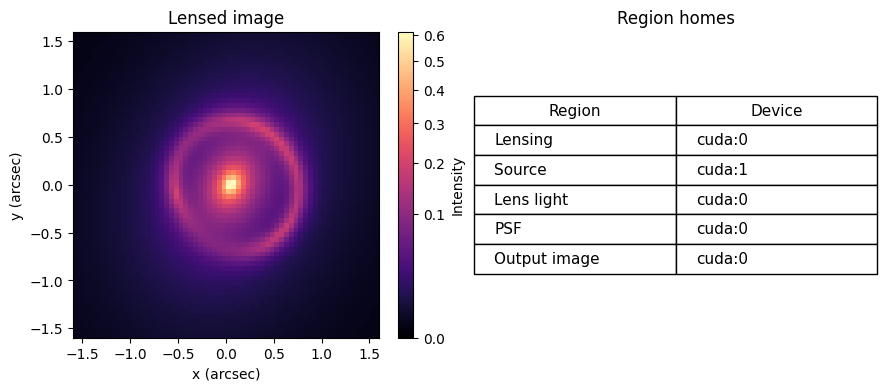

In [2]:
regions = [
    ("Lensing", str(sim.lens.z_l.device)),
    ("Source", str(sim.source.Re.device)),
    ("Lens light", str(sim.lens_light.Re.device)),
    ("PSF", str(sim.psf.device)),
    ("Output image", str(image.device)),
]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
artist = axes[0].imshow(
    image.detach().cpu().numpy(),
    origin="lower",
    extent=(-1.6, 1.6, -1.6, 1.6),
    cmap="magma",
    norm=PowerNorm(0.5, vmin=0, vmax=float(reference.max())),
)
axes[0].set(title="Lensed image", xlabel="x (arcsec)", ylabel="y (arcsec)")
fig.colorbar(artist, ax=axes[0], label="Intensity")
axes[1].axis("off")
axes[1].set_title("Region homes")
table = axes[1].table(
    cellText=regions, colLabels=("Region", "Device"), cellLoc="left", loc="center"
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.1, 1.7)
plt.show()

Migration must preserve the derivative for every packed physical parameter. The next cell checks all 21 components against the native, co-located reference.

In [3]:
q = params.clone().requires_grad_()
loss = sim(q).square().sum()
gradient = torch.autograd.grad(loss, q)[0]
assert gradient.device == home and gradient.numel() == 21
actual = gradient.detach().cpu()
torch.testing.assert_close(actual, native_gradient, atol=1e-9, rtol=1e-8)
error = (actual - native_gradient).abs()
worst = int(error.argmax())
print("All 21 parameter gradients agree.")
print("Maximum absolute difference:", float(error.max()), "at", problem.names[worst])
print("Reference magnitude there:", abs(float(native_gradient[worst])))
print(
    "Relative L2 difference:",
    float(
        torch.linalg.vector_norm(actual - native_gradient)
        / torch.linalg.vector_norm(native_gradient).clamp_min(torch.finfo(actual.dtype).eps)
    ),
)
del q, loss, gradient

All 21 parameter gradients agree.
Maximum absolute difference: 2.842170943040401e-14 at source.Ie
Reference magnitude there: 173.33295959322237
Relative L2 difference: 5.688279544236528e-17


G:\Qsync\Maitrise\Projects\Niagara\.venv\Lib\site-packages\torch\autograd\graph.py:882: UserWarning: The AccumulateGrad node's stream does not match the stream of the node that produced the incoming gradient. This may incur unnecessary synchronization and break CUDA graph capture if the AccumulateGrad node's stream is the default stream. This mismatch is caused by an AccumulateGrad node created prior to the current iteration being kept alive. This can happen if the autograd graph is still being kept alive by tensors such as the loss, or if you are using DDP, which will stash a reference to the node. To resolve the mismatch, delete all references to the autograd graph or ensure that DDP initialization is performed under the same stream as subsequent forwards. If the mismatch is intentional, you can use torch.autograd.graph.set_warn_on_accumulate_grad_stream_mismatch(False) to suppress this warning. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\inpu

Keys may be node identities or paths such as `"source"` and `"sim.source"`.
Identity keys are useful when a node has multiple aliases. CPU is supported;
CUDA indices must be explicit and available. A bare `"cuda"` is rejected.

## Validation precedes migration

Niagara rejects active reassignment, unavailable devices, inconsistent aliases,
ambiguous shared ownership and nodes owned outside the supplied common root.
A shared module/parameter needs one inherited home or an explicit identity
assignment that resolves the ambiguity.

Pointer edges are references rather than ordinary ownership. A pointer callable
must be able to evaluate all its declared dependencies on a common device.
The result may cross a region boundary through differentiable copies. Dependencies
visible only through a pointer need explicit homes when ownership cannot be
inferred. Invisible Python closure dependencies are outside the validated DAG.

## Migration and tensor factories

Placement migrates parameter state and tensor pytrees held in module
attributes, including private Caustics grids/kernels. It does not inspect
arbitrary opaque Python objects for hidden tensors. Put migratable state in
ordinary tensor attributes or linked parameters.

A tensor factory inside a model body must use the correct explicit device or
derive it from an input, for example `x.new_tensor(0.5)`. Check device-specific
factories in model code; placement cannot repair them all after execution.

Inputs and filled parameter arguments move at `@forward` boundaries. Child
results return to the calling region's home. The normal routing path uses
PyTorch copy semantics without global CUDA synchronization.

## Diagnostics and closing

In [4]:
placement.reset_diagnostics()
image = sim(params)
info = placement.diagnostics()
for path in ("sim", "sim.lens", "sim.source", "sim.lens_light"):
    print(f"{path:18s}", info["homes"][path])
print("Explicit transfer calls:", info["transfers"])
print("Explicit transfer bytes:", info["bytes"])
print(
    "Source calls observed:", [call for call in info["observed_calls"] if call[0] == "sim.source"]
)
placement.reset_diagnostics()
print("Transfer counters after reset:", placement.diagnostics()["transfers"])

sim                cuda:0
sim.lens           cuda:0
sim.source         cuda:1
sim.lens_light     cuda:0
Explicit transfer calls: {'cuda:0->cuda:1': 10, 'cuda:1->cuda:0': 1}
Explicit transfer bytes: {'cuda:0->cuda:1': 78624, 'cuda:1->cuda:0': 39200}
Source calls observed: [('sim.source', 'cuda:1')]
Transfer counters after reset: {}


The counters track instrumented routing calls. Captured graphs can bypass
those Python boundaries. Use a CUDA profile to measure prepared execution
and implicit backward traffic.

`Placement.close()` restores native classes and leaves tensors at their current
homes. If native Caskade requires co-location, close the old placement, apply a uniform plan and close that plan, or use the high-level backend whose close contract does that for you.
Changing graph structure or moving state manually invalidates prepared work;
close the old placement and validate a new one.

## Restore native execution

Close the split routing handle, apply a uniform plan, then close that plan to resume native calls. Closing the split handle alone leaves tensors on their old homes.

In [5]:
placement.close()
print("Source home after low-level close:", sim.source.Re.device)
uniform = ng.assign_devices(sim, ng.DevicePlan(default=home))
uniform.close()
restored = sim(params)
assert type(sim) is native_class and sim.source.Re.device == home
torch.testing.assert_close(restored.detach().cpu(), reference, atol=1e-10, rtol=1e-9)
print("Native class:", type(sim).__name__, "restored source home:", sim.source.Re.device)

Source home after low-level close: cuda:1
Native class: LensSource restored source home: cuda:0
